In [1]:
# Insitu rainfall — Seasonal variogram calibration + monthly ordinary kriging
# Derives variogram parameters from climatological station means per season,
# then produces one 1km WGS84 GeoTIFF per month.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob
 
from pyproj import Proj
from scipy.optimize import curve_fit
from scipy.spatial.distance import pdist, squareform
from scipy.ndimage import gaussian_filter
 
import rasterio
from rasterio.transform import from_origin
from rasterio.enums import Resampling
from rasterio.warp import calculate_default_transform, reproject
import rioxarray as rxr
 
import geostatspy.geostats as geostats
import geostatspy.GSLIB as GSLIB

In [2]:
# ── Input data ────────────────────────────────────────────────────────────────
INSITU_CSV      = r"..\Data\Processed\Insitu\insitu_rainfall_1991_2020.csv"
TRAIN_STATIONS  = r"..\Data\Processed\Split_stations\train_stations.csv"
TEST_STATIONS   = r"..\Data\Processed\Split_stations\test_stations.csv"
 
# ── Template raster (defines output grid extent and CRS) ─────────────────────
# WGS84 ~1km template — sole reference for output grid extent, resolution,
# and pixel registration.  The UTM kriging grid is derived from its bounds.
TEMPLATE_WGS84  = r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_max.tif"
 
# ── Calibration period for variogram fitting ──────────────────────────────────
# Adjust for final run (e.g. 1991–2020 for full period)
CALIB_START_YEAR = 2001
CALIB_END_YEAR   = 2005
 
# ── Processing period for kriging output ──────────────────────────────────────
KRIG_START_YEAR  = 2001
KRIG_START_MONTH = 1
KRIG_END_YEAR    = 2005
KRIG_END_MONTH   = 12
 
# ── Variogram parameters ──────────────────────────────────────────────────────
LAG_DIST    = 50.0       # km — lag spacing (rule of thumb: domain/12)
LAG_TOL     = 25.0       # km — half the lag distance
N_LAG       = 12         # number of lag classes → max lag ~600 km
BANDWH      = 9999       # bandwidth (omnidirectional)
TMIN, TMAX  = -9999, 9999
MIN_PAIRS   = 10         # minimum pairs per bin to use in fitting
SILL_TARGET = 0.8        # sill fraction used for isotropy range estimation
 
# ── Station / data completeness thresholds ────────────────────────────────────
COMPLETENESS_THRESHOLD = 0.80   # min fraction of expected days with valid records
                                 # per station-year-season; below this the
                                 # station-year is dropped before averaging
 
# ── Kriging fallback thresholds ───────────────────────────────────────────────
WET_STATION_THRESHOLD = 1.0     # mm — defines a "wet" station
WET_PERCENT_MIN       = 0.05    # <5% wet stations → bilinear fallback
MIN_STATION_FRACTION  = 0.20    # <20% of train stations available → bilinear fallback
 
# ── Output ────────────────────────────────────────────────────────────────────
OUTPUT_DIR  = r"..\Data\Processed\Kriging_Predictors\Insitu_kriged"
TEMP_DIR    = r"..\Data\Processed\Kriging_Predictors\Insitu_kriged\Temp"
VAR_DIR     = r"..\Data\Processed\Variogram_analysis\Insitu"
 
GRID_RES_KM = 1.0       # output resolution in km
NODATA_OUT  = -9999.0
 
# ── Model display colours ─────────────────────────────────────────────────────
COLORS = {'spherical': 'steelblue', 'exponential': 'darkorange', 'gaussian': 'forestgreen'}

In [3]:
# 1 — FIXED CONSTANTS (do not need regular adjustment) 
 
UTM_PROJ   = "+proj=utm +zone=45 +ellps=WGS84 +datum=WGS84 +units=m +no_defs"
MODEL_IT   = {'spherical': 1, 'exponential': 2, 'gaussian': 3}
GSLIB_SENTINEL = 9.966e+20
 
SEASONS = {
    'winter':       [12, 1, 2],
    'pre_monsoon':  [3, 4, 5],
    'monsoon':      [6, 7, 8, 9],
    'post_monsoon': [10, 11],
}
 
SEASON_EXPECTED_DAYS = {
    'winter': 90, 'pre_monsoon': 92, 'monsoon': 122, 'post_monsoon': 61
}
 
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(TEMP_DIR,   exist_ok=True)
os.makedirs(VAR_DIR,    exist_ok=True)
 
PARAMS_CSV = os.path.join(VAR_DIR, "variogram_params_insitu.csv")
if os.path.exists(PARAMS_CSV):
    os.remove(PARAMS_CSV)

In [4]:
# ── SECTION 2 — HELPER FUNCTIONS 
 
def get_season(month):
    for s, months in SEASONS.items():
        if month in months:
            return s
    return None
 
# Single Proj instance shared by all sections
proj_utm = Proj(UTM_PROJ)
 
def coords_to_utm_km(lons, lats):
    x_m, y_m = proj_utm(lons, lats)
    return x_m / 1000.0, y_m / 1000.0
 
def mask_gslib_sentinel(arr, threshold=1e10):
    return np.where(np.abs(arr) > threshold, np.nan, arr.astype(float))
 
def safe_nscore_lookup(ns_pred, lookup_df):
    lut = lookup_df.sort_values('nscore_value').drop_duplicates('nscore_value')
    return np.interp(ns_pred, lut['nscore_value'].values, lut['original_value'].values)
 
# ── Variogram model functions (identical to ERA5-L script) ────────────────────
 
def spherical(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    sph = np.where(
        h <= range_,
        nugget + partial_sill * (1.5*(h/range_) - 0.5*(h/range_)**3),
        nugget + partial_sill
    )
    return np.where(h == 0, nugget, sph)
 
def exponential(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-h / (range_/3))))
 
def gaussian(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-(h**2) / (range_/3)**2)))
 
MODEL_FUNCTIONS = {
    'spherical':   spherical,
    'exponential': exponential,
    'gaussian':    gaussian,
}
 
# ── WLS fitting (identical structure to ERA5-L script) ────────────────────────
 
def fit_model_wls(func, lag_fit, gamma_fit, sigma, p0, bounds):
    popt, _ = curve_fit(
        func, lag_fit, gamma_fit,
        p0=p0, sigma=sigma, absolute_sigma=True,
        bounds=bounds, maxfev=10000
    )
    return popt
 
def iterative_wls(func, lag_fit, gamma_fit, npairs_fit, p0, bounds,
                  n_bins, n_iter=3, conv_tol=0.01):
    """Iteratively reweighted WLS — mirrors ERA5-L implementation."""
    warm_w = npairs_fit / np.maximum(lag_fit**2, 1e-6)
    warm_w = warm_w / warm_w.sum() * n_bins
    sigma  = 1.0 / np.sqrt(np.maximum(warm_w, 1e-12))
 
    try:
        popt = fit_model_wls(func, lag_fit, gamma_fit, sigma, p0, bounds)
    except RuntimeError:
        raise RuntimeError("Warm-start fit failed")
 
    history, converged = [popt.copy()], False
 
    for _ in range(1, n_iter + 1):
        gamma_model = func(lag_fit, *popt)
        w      = npairs_fit / np.maximum(gamma_model, 1e-6)**2
        w      = w / w.sum() * n_bins
        sigma  = 1.0 / np.sqrt(np.maximum(w, 1e-12))
 
        try:
            popt_new = fit_model_wls(func, lag_fit, gamma_fit, sigma, popt, bounds)
        except RuntimeError:
            break
 
        rel_change = np.abs((popt_new - popt) / np.maximum(np.abs(popt), 1e-9))
        history.append(popt_new.copy())
        popt = popt_new
 
        if rel_change.max() < conv_tol:
            converged = True
            break
 
    return popt, sigma, converged, history

In [5]:
# ── SECTION 3 — LOAD & PREPROCESS IN-SITU DATA 

insitu_raw = pd.read_csv(INSITU_CSV)
insitu_raw["date"] = pd.to_datetime(insitu_raw[["year", "month", "day"]])
insitu_raw = insitu_raw.rename(columns={
    "lat": "y", "long": "x", "rainfall_sum": "insitu_prec"
})
insitu_raw = insitu_raw[insitu_raw["insitu_prec"] >= 0]
 
insitu_monthly = (
    insitu_raw
    .groupby(["index_no", "y", "x", "year", "month"])
    .agg(
        insitu_monthly_total=("insitu_prec", "sum"),
        valid_days          =("insitu_prec", "count")
    )
    .reset_index()
)
 
train_ids = set(pd.read_csv(TRAIN_STATIONS)["index_no"])
test_ids  = set(pd.read_csv(TEST_STATIONS)["index_no"])
 
insitu_train_monthly = insitu_monthly[insitu_monthly["index_no"].isin(train_ids)].copy()
insitu_test_monthly  = insitu_monthly[insitu_monthly["index_no"].isin(test_ids)].copy()
 
# Total number of unique train stations in the full dataset
N_TRAIN_STATIONS = insitu_train_monthly["index_no"].nunique()
print(f"Total unique train stations: {N_TRAIN_STATIONS}")


Total unique train stations: 50


In [6]:
# ── SECTION 4 — VARIOGRAM CALIBRATION (seasonal climatological means) 

# ── Step 4a: Assign season labels, handle winter year-shift ──────────────────
 
def assign_season_year(df):
    """
    Adds 'season' and 'season_year' columns.
    December is assigned to the following year's winter
    (consistent with ERA5-L script).
    """
    df = df.copy()
    df['season'] = df['month'].map(get_season)
 
    def _season_year(row):
        if row['season'] == 'winter' and row['month'] == 12:
            return row['year'] + 1
        return row['year']
 
    df['season_year'] = df.apply(_season_year, axis=1)
    return df
 
train_seas = assign_season_year(insitu_train_monthly)
 
# ── Step 4b: Seasonal totals per station per year ─────────────────────────────
 
seasonal_totals = (
    train_seas
    .groupby(['index_no', 'y', 'x', 'season', 'season_year'])
    .agg(
        seasonal_total=('insitu_monthly_total', 'sum'),
        valid_days    =('valid_days',           'sum')
    )
    .reset_index()
)
 
# ── Step 4c: Completeness filter ──────────────────────────────────────────────
# Drop station-year-season rows where valid_days < threshold × expected days
 
seasonal_totals['expected_days'] = seasonal_totals['season'].map(SEASON_EXPECTED_DAYS)
seasonal_totals['completeness']  = (
    seasonal_totals['valid_days'] / seasonal_totals['expected_days']
)
before = len(seasonal_totals)
seasonal_totals = seasonal_totals[
    seasonal_totals['completeness'] >= COMPLETENESS_THRESHOLD
].copy()
after = len(seasonal_totals)
print(f"Completeness filter: dropped {before - after} station-year-season rows "
      f"(threshold={COMPLETENESS_THRESHOLD*100:.0f}%)")
 
# ── Step 4d: Calibration period filter ────────────────────────────────────────
calib_mask = (
    (seasonal_totals['season_year'] >= CALIB_START_YEAR) &
    (seasonal_totals['season_year'] <= CALIB_END_YEAR)
)
seasonal_calib = seasonal_totals[calib_mask].copy()
print(f"Calibration period {CALIB_START_YEAR}–{CALIB_END_YEAR}: "
      f"{len(seasonal_calib)} station-year-season records")
 
# ── Step 4e: Climatological mean per station per season ───────────────────────
# One value per station per season → used for variogram fitting
 
clim_means = (
    seasonal_calib
    .groupby(['index_no', 'y', 'x', 'season'])
    .agg(clim_mean=('seasonal_total', 'mean'))
    .reset_index()
)
 
print(f"\nClimatological means per season:")
for s in SEASONS:
    n = (clim_means['season'] == s).sum()
    print(f"  {s}: {n} stations")

Completeness filter: dropped 305 station-year-season rows (threshold=80%)
Calibration period 2001–2005: 944 station-year-season records

Climatological means per season:
  winter: 50 stations
  pre_monsoon: 50 stations
  monsoon: 50 stations
  post_monsoon: 50 stations



════════════════════════════════════════════════════════════
  Season: winter
════════════════════════════════════════════════════════════
  Station count: 50 | Domain extent: 823 km
  Lag bins: 12 × 50.0 km | Lag cap: 412 km


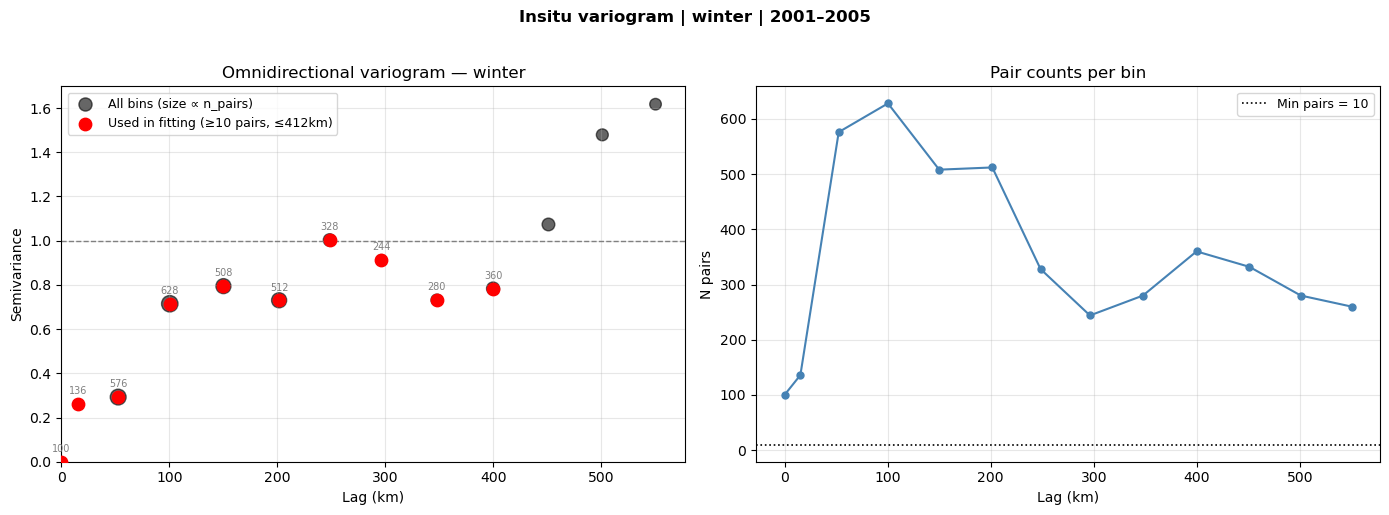

  spherical    nug=0.000 cc=0.784 range=139.8km R²=1.000 ⚠ SILL FLAG
  exponential  nug=0.000 cc=0.752 range=171.3km R²=1.000 ⚠ SILL FLAG
  gaussian     nug=0.000 cc=0.625 range=64.9km R²=1.000 ⚠ SILL FLAG


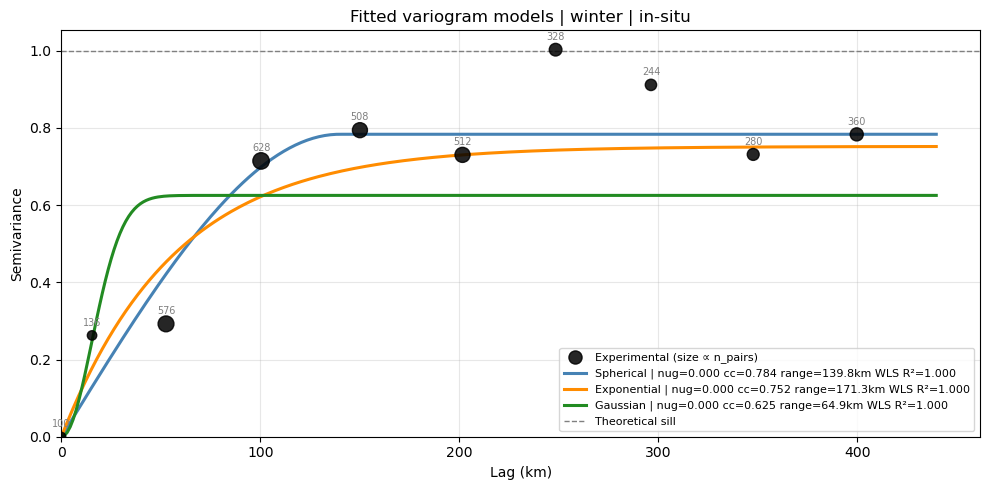


  ✓ Best model: GAUSSIAN
  Row saved → ..\Data\Processed\Variogram_analysis\Insitu\variogram_params_insitu.csv

════════════════════════════════════════════════════════════
  Season: pre_monsoon
════════════════════════════════════════════════════════════
  Station count: 50 | Domain extent: 823 km
  Lag bins: 12 × 50.0 km | Lag cap: 412 km


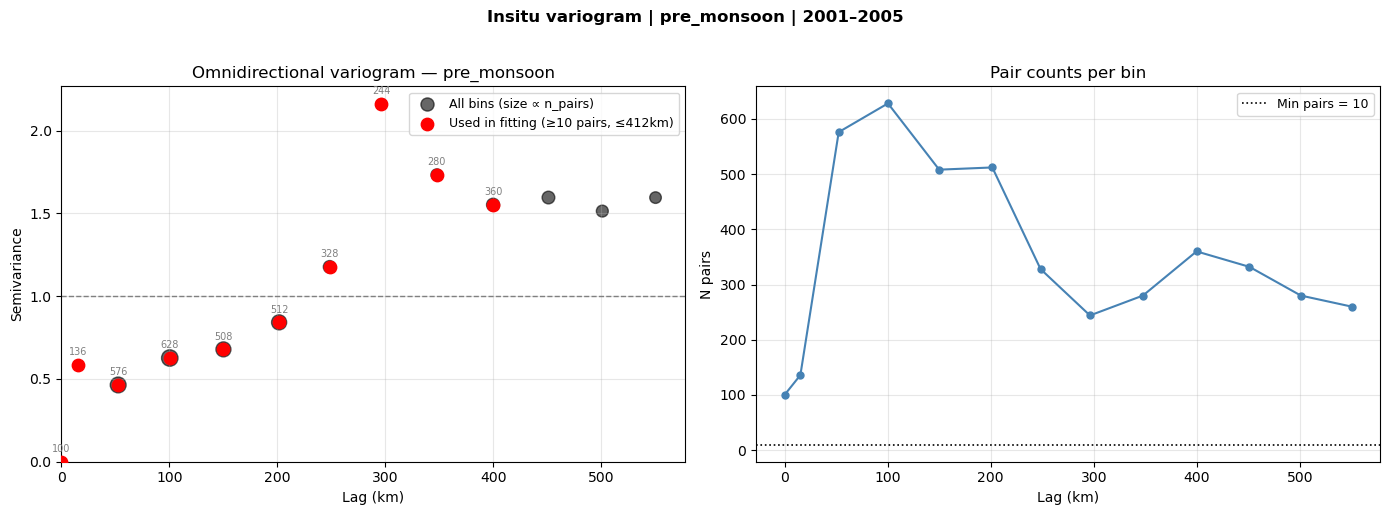

  spherical    nug=0.000 cc=0.883 range=50.0km R²=1.000 ✓
  exponential  nug=0.000 cc=1.000 range=226.1km R²=1.000 ✓
  gaussian     nug=0.000 cc=0.866 range=50.0km R²=1.000 ✓


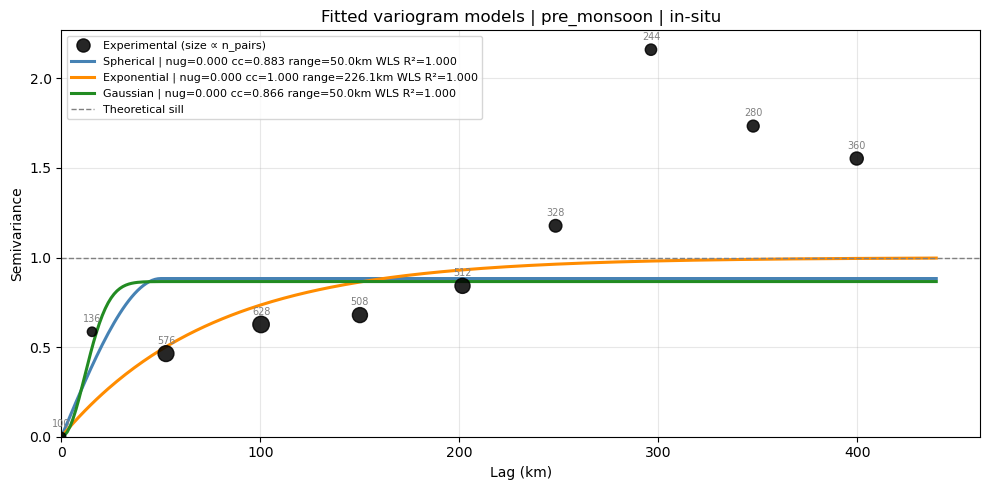


  ✓ Best model: EXPONENTIAL
  Row saved → ..\Data\Processed\Variogram_analysis\Insitu\variogram_params_insitu.csv

════════════════════════════════════════════════════════════
  Season: monsoon
════════════════════════════════════════════════════════════
  Station count: 50 | Domain extent: 823 km
  Lag bins: 12 × 50.0 km | Lag cap: 412 km


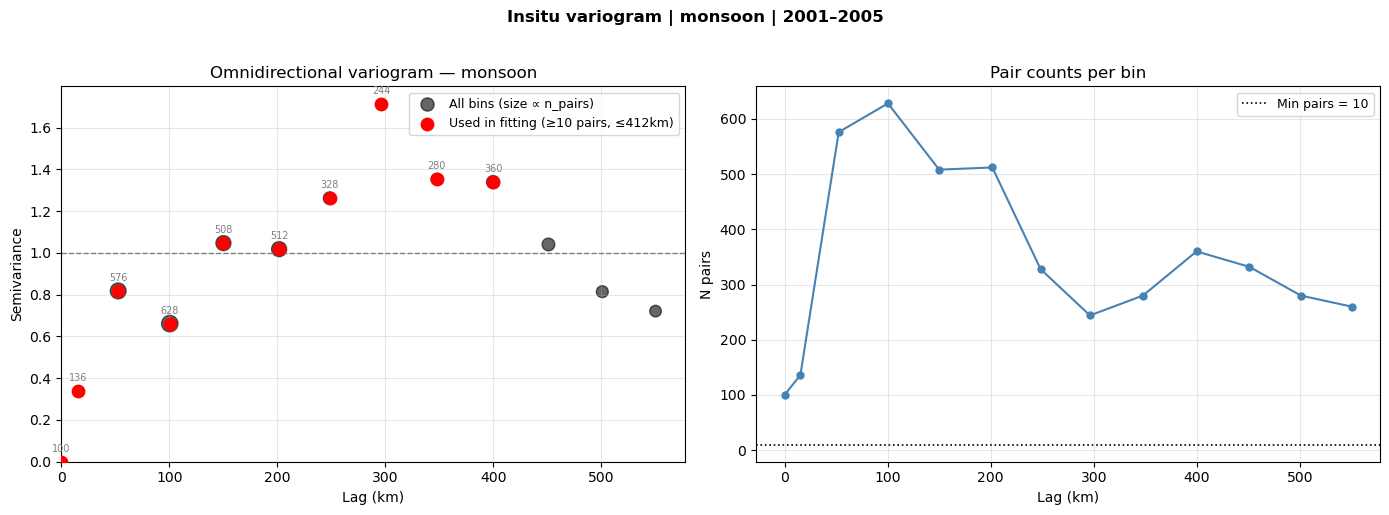

  spherical    nug=0.000 cc=0.983 range=75.7km R²=1.000 ✓
  exponential  nug=0.000 cc=0.975 range=104.8km R²=1.000 ✓
  gaussian     nug=0.000 cc=0.930 range=69.4km R²=1.000 ✓


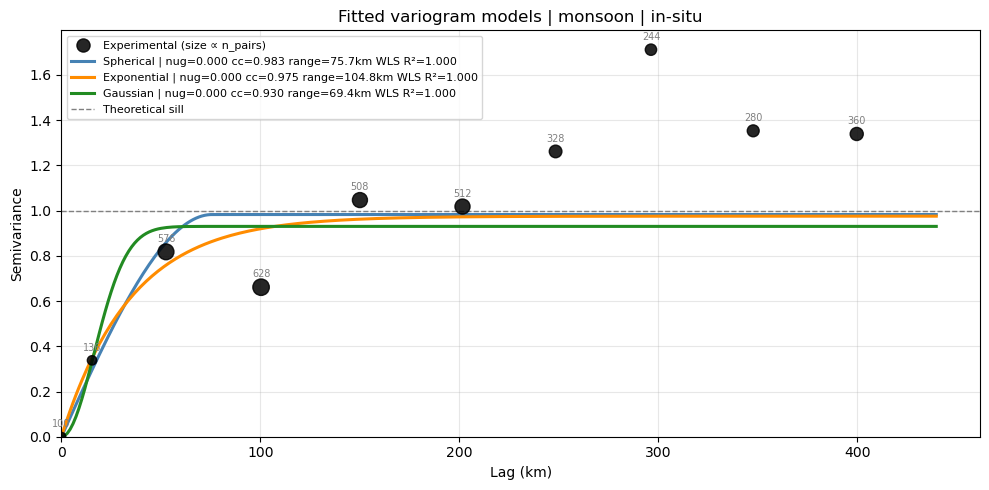


  ✓ Best model: SPHERICAL
  Row saved → ..\Data\Processed\Variogram_analysis\Insitu\variogram_params_insitu.csv

════════════════════════════════════════════════════════════
  Season: post_monsoon
════════════════════════════════════════════════════════════
  Station count: 50 | Domain extent: 823 km
  Lag bins: 12 × 50.0 km | Lag cap: 412 km


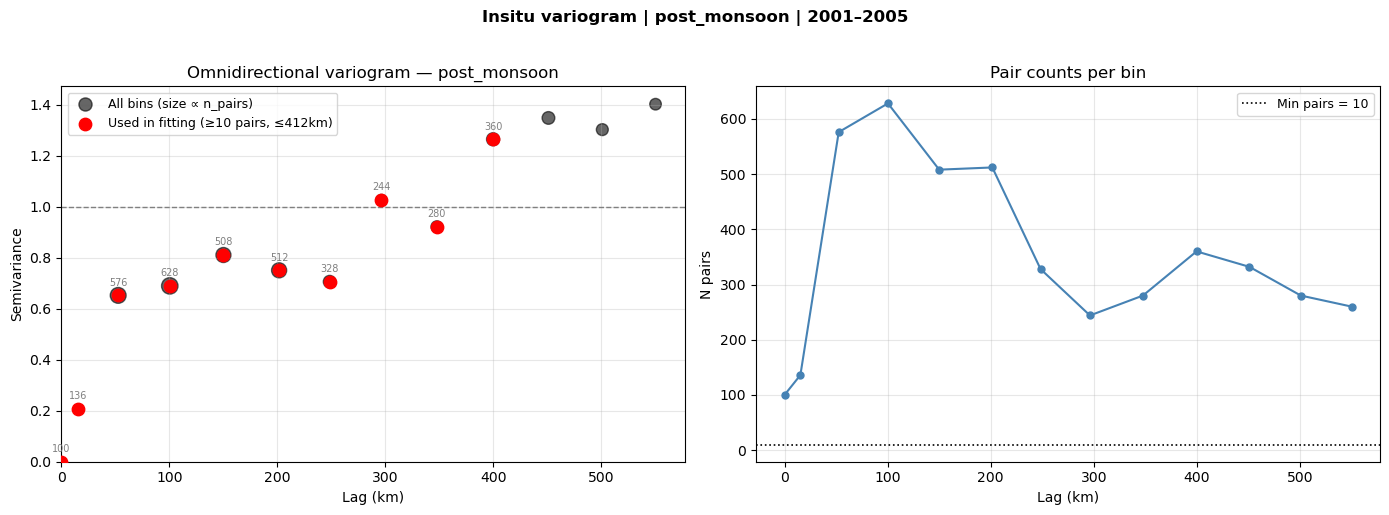

  spherical    nug=0.000 cc=0.754 range=79.5km R²=1.000 ⚠ SILL FLAG
  exponential  nug=0.000 cc=0.870 range=144.1km R²=1.000 ✓
  gaussian     nug=0.000 cc=0.828 range=96.1km R²=1.000 ✓


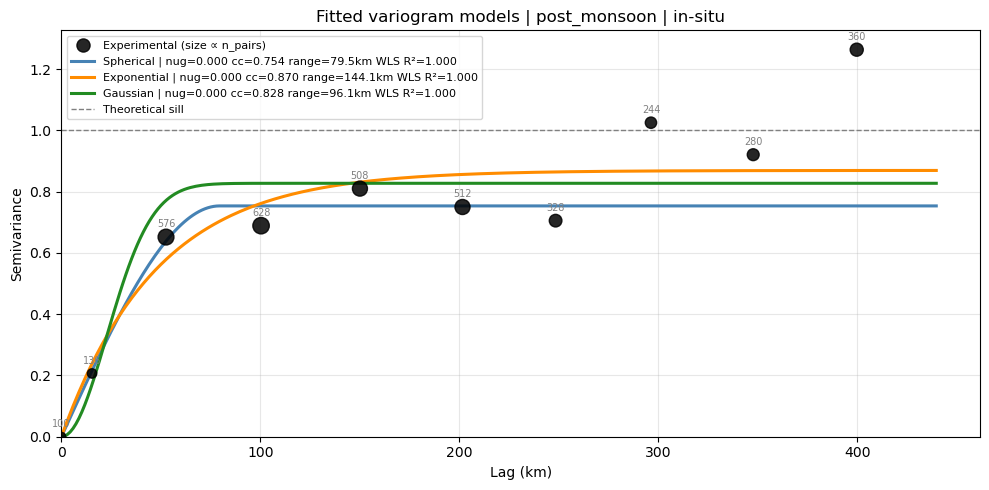


  ✓ Best model: GAUSSIAN
  Row saved → ..\Data\Processed\Variogram_analysis\Insitu\variogram_params_insitu.csv

════════════════════════════════════════════════════════════
  Variogram calibration complete → ..\Data\Processed\Variogram_analysis\Insitu\variogram_params_insitu.csv
════════════════════════════════════════════════════════════


In [7]:
# ── SECTION 5 — SEASONAL VARIOGRAM FITTING 

for season in SEASONS:
    print(f"\n{'═'*60}")
    print(f"  Season: {season}")
    print(f"{'═'*60}")
    notes = []
 
    # ── Subset to this season ─────────────────────────────────────────────
    df_s = clim_means[clim_means['season'] == season].copy().reset_index(drop=True)
 
    if len(df_s) < 10:
        print(f"  ⚠ Skipping — only {len(df_s)} stations with valid climatology")
        continue
 
    # ── Project to UTM km (shifted x to avoid negative coords in gamv) ───
    x_m_true, y_m = proj_utm(df_s['x'].values, df_s['y'].values)
    # Use the same X_OFFSET_M computed in Section 6 if available, else compute
    # a local offset just for variogram fitting (pure distance metric — offset
    # cancels out in pair distances so variogram shape is unaffected)
    _x_min_true = x_m_true.min()
    _x_off = int(np.ceil(-_x_min_true / 1000)) * 1000 if _x_min_true < 0 else 0
    df_s['x_km'] = (x_m_true + _x_off) / 1000.0
    df_s['y_km'] = y_m / 1000.0
 
    # ── N-score transform on climatological means ─────────────────────────
    ns_data, t_values, t_nscore = geostats.nscore(
        pd.DataFrame({'val': df_s['clim_mean'].values}), 'val'
    )
    df_s['ns'] = ns_data
    sample_var_ns = float(np.var(ns_data))
 
    if abs(sample_var_ns - 1.0) > 0.2:
        notes.append(f"nscore_var={sample_var_ns:.3f}")
 
    lookup_path = os.path.join(VAR_DIR, f"nscore_lookup_{season}_insitu.csv")
    pd.DataFrame({'original_value': t_values, 'nscore_value': t_nscore}).to_csv(
        lookup_path, index=False
    )
 
    # ── Omnidirectional experimental variogram ────────────────────────────
    # With only ~50 stations, directional analysis has too few pairs per bin.
    # We go straight to omnidirectional (azm=0, atol=90 → all directions).
    cluster_extent = pdist(df_s[['x_km', 'y_km']].values).max()
    lag_cap        = cluster_extent / 2.0
 
    lag_exp, gamma_exp, n_pairs = geostats.gamv(
        df_s, 'x_km', 'y_km', 'ns',
        TMIN, TMAX,
        LAG_DIST, LAG_TOL, N_LAG,
        0, 90, BANDWH, isill=0          # azm=0, atol=90 → omnidirectional
    )
 
    print(f"  Station count: {len(df_s)} | Domain extent: {cluster_extent:.0f} km")
    print(f"  Lag bins: {N_LAG} × {LAG_DIST} km | Lag cap: {lag_cap:.0f} km")
 
    valid_bins  = (n_pairs >= MIN_PAIRS) & (lag_exp <= lag_cap) & np.isfinite(gamma_exp)
    lag_fit     = lag_exp[valid_bins]
    gamma_fit   = gamma_exp[valid_bins]
    npairs_fit  = n_pairs[valid_bins]
    n_bins      = len(lag_fit)
 
    if n_bins < 4:
        print(f"  ⚠ Skipping — only {n_bins} valid bins after pair/cap filter")
        continue
 
    # ── Plot experimental variogram (diagnostic) ──────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
    scatter_sizes_all = (n_pairs / max(n_pairs.max(), 1)) * 120 + 20
    valid_all = np.isfinite(gamma_exp) & (n_pairs > 0)
    axes[0].scatter(lag_exp[valid_all], gamma_exp[valid_all],
                    s=scatter_sizes_all[valid_all], color='black', alpha=0.6,
                    label='All bins (size ∝ n_pairs)')
    axes[0].scatter(lag_fit, gamma_fit, s=80, color='red', zorder=5,
                    label=f'Used in fitting (≥{MIN_PAIRS} pairs, ≤{lag_cap:.0f}km)')
    for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
        axes[0].annotate(str(int(n)), (h, g), textcoords='offset points',
                         xytext=(0, 7), ha='center', fontsize=7, color='gray')
    axes[0].axhline(1.0, color='gray', linestyle='--', linewidth=1)
    axes[0].set(xlabel='Lag (km)', ylabel='Semivariance',
                title=f'Omnidirectional variogram — {season}')
    axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
    axes[0].set_xlim(left=0); axes[0].set_ylim(bottom=0)
 
    axes[1].plot(lag_exp[valid_all], n_pairs[valid_all], 'o-', color='steelblue',
                 linewidth=1.5, markersize=5)
    axes[1].axhline(MIN_PAIRS, color='black', linestyle=':', linewidth=1.2,
                    label=f'Min pairs = {MIN_PAIRS}')
    axes[1].set(xlabel='Lag (km)', ylabel='N pairs', title='Pair counts per bin')
    axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)
 
    plt.suptitle(f'Insitu variogram | {season} | {CALIB_START_YEAR}–{CALIB_END_YEAR}',
                 fontweight='bold', y=1.02)
    plt.tight_layout(); plt.show()
 
    # ── Iterative WLS for all three models ────────────────────────────────
    range_init = float(lag_fit[np.argmax(gamma_fit >= SILL_TARGET)]
                       if (gamma_fit >= SILL_TARGET).any() else lag_fit.mean())
    p0     = [0.05, 0.90, range_init]
    bounds = ([0, 0, LAG_DIST], [1.0, 1.0, 2 * cluster_extent])
 
    wls_results  = {}
    model_params = {}
 
    for model_name, func in MODEL_FUNCTIONS.items():
        try:
            popt, sigma_final, converged, history = iterative_wls(
                func, lag_fit, gamma_fit, npairs_fit, p0, bounds, n_bins
            )
            nugget, partial_sill, range_km = popt
            gamma_model = func(lag_fit, *popt)
 
            ss_res   = np.sum(((gamma_fit - gamma_model) / sigma_final)**2)
            ss_tot   = np.sum(((gamma_fit - gamma_fit.mean()) / sigma_final)**2)
            wls_r2   = float(1 - ss_res / ss_tot) if ss_tot > 1e-12 else np.nan
            wls_rmse = float(np.sqrt(np.mean((gamma_fit - gamma_model)**2)))
            sill_flag = abs(nugget + partial_sill - 1.0) > 0.2
 
            # Gaussian condition number check (same as ERA5-L script)
            if model_name == 'gaussian':
                D        = squareform(pdist(df_s[['x_km', 'y_km']].values))
                sill_val = nugget + partial_sill
                cov_mat  = sill_val - func(D, nugget, partial_sill, range_km)
                n_pts    = len(df_s)
                C_ok     = np.ones((n_pts+1, n_pts+1))
                C_ok[:n_pts, :n_pts] = cov_mat
                C_ok[n_pts, n_pts]   = 0.0
                cond_number  = float(np.linalg.cond(C_ok))
                disqualified = cond_number > 1e5
                disq_reason  = f'cond_number={cond_number:.2e}' if disqualified else None
            else:
                cond_number  = np.nan
                disqualified = False
                disq_reason  = None
 
            if sill_flag:
                notes.append(f"{model_name}_sill_flag")
 
            wls_results[model_name] = {
                'func':         func,
                'nugget':       float(nugget),
                'partial_sill': float(partial_sill),
                'total_sill':   float(nugget + partial_sill),
                'range_km':     float(range_km),
                'wls_r2':       wls_r2,
                'wls_rmse':     wls_rmse,
                'sigma_final':  sigma_final,
                'sill_flag':    sill_flag,
                'cond_number':  cond_number,
                'disqualified': disqualified,
                'disq_reason':  disq_reason,
            }
            model_params[model_name] = {
                'nugget':       float(nugget),
                'partial_sill': float(partial_sill),
                'range_km':     float(range_km),
            }
 
            status = '⚠ DISQUALIFIED' if disqualified else ('⚠ SILL FLAG' if sill_flag else '✓')
            print(f"  {model_name:<12} nug={nugget:.3f} cc={partial_sill:.3f} "
                  f"range={range_km:.1f}km R²={wls_r2:.3f} {status}")
 
        except RuntimeError as e:
            print(f"  {model_name:<12} FAILED — {e}")
            wls_results[model_name] = {
                'disqualified': True, 'disq_reason': str(e),
                'wls_r2': np.nan, 'cond_number': np.nan
            }
 
    # ── Parameter override block ──────────────────────────────────────────
    # Uncomment and adjust if you want to manually override fitted params:
    # model_params['spherical']['nugget']         = 0.05
    # model_params['spherical']['partial_sill']   = 0.88
    # model_params['spherical']['range_km']       = 200.0
    # model_params['exponential']['nugget']       = 0.05
    # model_params['exponential']['partial_sill'] = 0.90
    # model_params['exponential']['range_km']     = 250.0
    # model_params['gaussian']['nugget']          = 0.02
    # model_params['gaussian']['partial_sill']    = 0.92
    # model_params['gaussian']['range_km']        = 180.0
 
    # ── Visual comparison of fitted models ────────────────────────────────
    h_plot  = np.linspace(0, lag_fit.max() * 1.1, 300)
    fig, ax = plt.subplots(figsize=(10, 5))
 
    scatter_sizes = (npairs_fit / npairs_fit.max()) * 120 + 20
    ax.scatter(lag_fit, gamma_fit, s=scatter_sizes, color='black',
               zorder=5, label='Experimental (size ∝ n_pairs)', alpha=0.85)
    for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
        ax.annotate(str(int(n)), (h, g), textcoords='offset points',
                    xytext=(0, 7), ha='center', fontsize=7, color='gray')
 
    qualified_models = {
        m: p for m, p in model_params.items()
        if not wls_results[m].get('disqualified', False)
    }
    for model_name, params in qualified_models.items():
        gamma_curve = MODEL_FUNCTIONS[model_name](
            h_plot, params['nugget'], params['partial_sill'], params['range_km']
        )
        wls_r2 = wls_results[model_name]['wls_r2']
        ax.plot(h_plot, gamma_curve, color=COLORS[model_name], linewidth=2.2,
                label=(f"{model_name.capitalize()} | nug={params['nugget']:.3f} "
                       f"cc={params['partial_sill']:.3f} range={params['range_km']:.1f}km "
                       f"WLS R²={wls_r2:.3f}"))
 
    ax.axhline(1.0, color='gray', linestyle='--', linewidth=1, label='Theoretical sill')
    ax.set(xlabel='Lag (km)', ylabel='Semivariance',
           title=f'Fitted variogram models | {season} | in-situ')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    plt.tight_layout(); plt.show()
 
    # ── Model selection (max WLS R²) ──────────────────────────────────────
    qualified_for_select = {
        m: wls_results[m] for m in qualified_models
        if not wls_results[m].get('sill_flag', False)
        and not wls_results[m].get('disqualified', False)
    }
    if not qualified_for_select:
        qualified_for_select = {
            m: wls_results[m] for m in qualified_models
            if not wls_results[m].get('disqualified', False)
        }
        notes.append('no_model_passed_sill_check')
 
    if not qualified_for_select:
        print(f"  ⚠ All models failed — skipping season")
        continue
 
    best_model  = max(qualified_for_select, key=lambda m: wls_results[m]['wls_r2'])
    best_params = model_params[best_model]
    best_wls    = wls_results[best_model]
 
    if best_wls['wls_r2'] < 0.5:
        notes.append('wls_r2<0.5')
    if best_params['nugget'] > 0.5 * best_wls.get('total_sill', 1.0):
        notes.append('nugget_dominated')
    if best_params['range_km'] < 1.5 * LAG_DIST:
        notes.append('range_too_short')
 
    print(f"\n  ✓ Best model: {best_model.upper()}")
 
    # ── Save variogram parameters ─────────────────────────────────────────
    row = {
        'season':             season,
        'n_stations':         len(df_s),
        'calib_start':        CALIB_START_YEAR,
        'calib_end':          CALIB_END_YEAR,
        'nscore_lookup_path': lookup_path,
        'sample_var_ns':      round(sample_var_ns, 6),
        'model_type':         best_model,
        'nugget':             round(best_params['nugget'],       6),
        'partial_sill':       round(best_params['partial_sill'], 6),
        'range_km':           round(best_params['range_km'],     3),
        'azimuth_major':      0,       # omnidirectional → isotropic
        'wls_r2':             round(best_wls['wls_r2'],          6),
        'notes':              '; '.join(notes) if notes else '',
    }
    header = not os.path.exists(PARAMS_CSV)
    pd.DataFrame([row]).to_csv(PARAMS_CSV, mode='a', header=header, index=False)
    print(f"  Row saved → {PARAMS_CSV}")
 
print(f"\n{'═'*60}")
print(f"  Variogram calibration complete → {PARAMS_CSV}")
print(f"{'═'*60}") 

In [8]:
from pykrige.ok import OrdinaryKriging

# 1. Project template bounds to UTM to get coordinates for the 1km grid
with rasterio.open(TEMPLATE_WGS84) as tmp:
    dst_crs = 'EPSG:32645'
    transform_utm, width_utm, height_utm = calculate_default_transform(
        tmp.crs, dst_crs, tmp.width, tmp.height, *tmp.bounds
    )
    out_profile_wgs84 = tmp.profile.copy()

# 2. Create the 1D coordinate vectors for the grid (in meters)
# PyKrige likes the coordinates where the data actually sits.
grid_x = np.linspace(transform_utm[2], transform_utm[2] + (width_utm * transform_utm[0]), width_utm)
grid_y = np.linspace(transform_utm[5] + (height_utm * transform_utm[4]), transform_utm[5], height_utm)

# Note: grid_y is South -> North (ascending) for PyKrige logic

In [9]:
var_params_all = pd.read_csv(PARAMS_CSV).set_index('season')
log_rows = []

# Generate list of months to process
target_months = []
for y in range(KRIG_START_YEAR, KRIG_END_YEAR + 1):
    for m in range(1, 13):
        if (y == KRIG_START_YEAR and m < KRIG_START_MONTH) or (y == KRIG_END_YEAR and m > KRIG_END_MONTH):
            continue
        target_months.append((y, m))
        
for year, month in target_months:
    date_str = f"{year}{month:02d}"
    season = get_season(month)
    
    df_m = insitu_train_monthly[(insitu_train_monthly['year'] == year) & 
                                (insitu_train_monthly['month'] == month)].copy()
    
    # Get UTM coordinates in METERS for PyKrige
    p = Proj(UTM_PROJ)
    df_m['x_m'], df_m['y_m'] = p(df_m['x'].values, df_m['y'].values)
    
    # Normal Score Transform
    ns_data, t_vals, t_ns = geostats.nscore(df_m, 'insitu_monthly_total')
    df_m['ns'] = ns_data
    lookup_df = pd.DataFrame({'original_value': t_vals, 'nscore_value': t_ns})

    # Get Variogram Params from your CSV
    vp = var_params_all.loc[season]
    
    # Initialize PyKrige Ordinary Kriging
    # PyKrige variogram_parameters: [psill, range, nugget]
    # Note: 'cc' in geostatspy is 'partial sill'
    ok = OrdinaryKriging(
        df_m['x_m'], df_m['y_m'], df_m['ns'],
        variogram_model=vp['model_type'],
        variogram_parameters={
            'sill': min(vp['partial_sill'], 0.85), 
            'range': max(100*1000, vp['range_km'] * 1000), # convert km to meters
            'nugget': max(0.15, vp['nugget'])
        }
    )

    # Execute Kriging on the grid
    # style='grid' returns a 2D array of the specified x and y coordinates
    # backend='loop' is slower but more memory efficient for 1km grids
    kmap, k_var = ok.execute('grid', grid_x, grid_y, backend='vectorized')

    # 7. Post-processing
    # PyKrige returns the grid with index [0,0] as the BOTTOM-LEFT.
    # We must flip it for Rasterio's TOP-LEFT requirement.
    kmap_flipped = np.flipud(kmap.data) 
    
    # Back-transform Normal Scores to Rainfall
    rain_grid = safe_nscore_lookup(kmap_flipped.flatten(), lookup_df).reshape(kmap_flipped.shape)
    rain_grid = np.clip(rain_grid, 0, None).astype('float32')

    # 8. Save directly to WGS84 via Reprojection
    utm_temp_path = os.path.join(TEMP_DIR, "temp_utm.tif")
    utm_meta = {
        'driver': 'GTiff', 'height': height_utm, 'width': width_utm, 'count': 1,
        'dtype': 'float32', 'crs': dst_crs, 'transform': transform_utm, 'nodata': NODATA_OUT
    }

    with rasterio.open(utm_temp_path, 'w', **utm_meta) as dst:
        dst.write(rain_grid, 1)

    # Final warp to match your template exactly
    final_path = os.path.join(OUTPUT_DIR, f"insitu_precip_{date_str}.tif")
    with rasterio.open(utm_temp_path) as src:
        with rasterio.open(final_path, 'w', **out_profile_wgs84) as dst:
            reproject(
                source=rasterio.band(src, 1),
                destination=rasterio.band(dst, 1),
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=dst.transform,
                dst_crs=dst.crs,
                resampling=Resampling.bilinear
            )
    print(f"  [OK] PyKrige output saved: {date_str}")

  [OK] PyKrige output saved: 200101
  [OK] PyKrige output saved: 200102
  [OK] PyKrige output saved: 200103
  [OK] PyKrige output saved: 200104
  [OK] PyKrige output saved: 200105
  [OK] PyKrige output saved: 200106
  [OK] PyKrige output saved: 200107
  [OK] PyKrige output saved: 200108
  [OK] PyKrige output saved: 200109
  [OK] PyKrige output saved: 200110
  [OK] PyKrige output saved: 200111
  [OK] PyKrige output saved: 200112
  [OK] PyKrige output saved: 200201
  [OK] PyKrige output saved: 200202
  [OK] PyKrige output saved: 200203
  [OK] PyKrige output saved: 200204
  [OK] PyKrige output saved: 200205
  [OK] PyKrige output saved: 200206
  [OK] PyKrige output saved: 200207
  [OK] PyKrige output saved: 200208
  [OK] PyKrige output saved: 200209
  [OK] PyKrige output saved: 200210
  [OK] PyKrige output saved: 200211
  [OK] PyKrige output saved: 200212
  [OK] PyKrige output saved: 200301
  [OK] PyKrige output saved: 200302
  [OK] PyKrige output saved: 200303
  [OK] PyKrige output saved: